# Actividad Individual 2 — EDA básico
**Análisis de Datos · CEIA FIUBA · 5B 2026**
**Alumno:** Leonardo Barahona
**Dataset:** Coffee Quality Database (Coffee Quality Institute) — vía [TidyTuesday 2020-07-07](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-07-07)

### Objetivo
Realizar un EDA básico: tipos de variables, estadística descriptiva, relaciones entre variables y al menos 3 gráficos distintos.

### Preguntas guía
1. ¿Cómo se distribuye la calidad del café (puntaje total de cata)?
2. ¿Qué atributos sensoriales están más relacionados con el puntaje total?
3. ¿La altitud se relaciona con la calidad?
4. ¿Cómo se compara Honduras con el resto de Centroamérica?
5. ¿El método de procesamiento se asocia con el país de origen?

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

URL = (
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/"
    "data/2020/2020-07-07/coffee_ratings.csv"
)
# Ruta relativa desde tps/act2-eda-basico/ hacia datos/raw/ de la materia
ARCHIVO = Path("../../datos/raw/coffee_ratings.csv")

if ARCHIVO.exists():
    df_raw = pd.read_csv(ARCHIVO)
else:
    df_raw = pd.read_csv(URL)

df_raw.shape

(1339, 43)

## 1. Primera inspección

In [2]:
df_raw.head()

,total_cup_points,species,owner,country_of_origin,farm_name,lot_number,mill,ico_number,company,altitude,region,producer,number_of_bags,bag_weight,in_country_partner,harvest_year,grading_date,owner_1,variety,processing_method,aroma,flavor,aftertaste,acidity,body,balance,uniformity,clean_cup,sweetness,cupper_points,moisture,category_one_defects,quakers,color,category_two_defects,expiration,certification_body,certification_address,certification_contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,90.58,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,NaN,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.00,10.00,10.00,8.75,0.12,0,0.00,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00
1,89.92,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.00,10.00,10.00,8.58,0.12,0,0.00,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00
2,89.75,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,NaN,NaN,5,1,Specialty Coffee Association,NaN,"May 31st, 2010",Grounds for Health Admin,Bourbon,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.00,10.00,10.00,9.25,0.00,0,0.00,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.00,1800.00,1700.00
3,89.00,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,oromia,Yidnekachew Dabessa Coffee Plantation,320,60 kg,METAD Agricultural Development plc,2014,"March 26th, 2015",Yidnekachew Dabessa,NaN,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.00,10.00,10.00,8.67,0.11,0,0.00,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.00,2200.00,2000.00
4,88.83,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.00,10.00,10.00,8.58,0.12,0,0.00,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1339 entries, 0 to 1338
Data columns (total 43 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   total_cup_points       1339 non-null   float64
 1   species                1339 non-null   str    
 2   owner                  1332 non-null   str    
 3   country_of_origin      1338 non-null   str    
 4   farm_name              980 non-null    str    
 5   lot_number             276 non-null    str    
 6   mill                   1021 non-null   str    
 7   ico_number             1180 non-null   str    
 8   company                1130 non-null   str    
 9   altitude               1113 non-null   str    
 10  region                 1280 non-null   str    
 11  producer               1107 non-null   str    
 12  number_of_bags         1339 non-null   int64  
 13  bag_weight             1339 non-null   str    
 14  in_country_partner     1339 non-null   str    
 15  harvest_year   

In [4]:
print("Filas duplicadas:", df_raw.duplicated().sum())
faltantes = df_raw.isna().mean().mul(100).sort_values(ascending=False)
faltantes[faltantes > 0].round(1).to_frame("% faltante")

Filas duplicadas: 0


,% faltante
lot_number,79.40
farm_name,26.80
mill,23.70
color,20.20
producer,17.30
altitude_high_meters,17.20
altitude_low_meters,17.20
altitude_mean_meters,17.20
altitude,16.90
variety,16.90


### 1.1 Selección de variables y ajustes mínimos
El dataset tiene 43 columnas, muchas administrativas (contactos, certificación, IDs). Para el EDA nos quedamos con las relevantes.

Ajustes mínimos (la limpieza formal se ve en la clase 4):
- Se excluye un lote con `total_cup_points = 0` (valor imposible: los puntajes van de ~60 a 100).
- Las altitudes > 5000 m se marcan como faltantes (no existen fincas de café a esa altura; probablemente error de unidades).

In [5]:
numericas = [
    "total_cup_points", "aroma", "flavor", "aftertaste", "acidity", "body",
    "balance", "altitude_mean_meters", "moisture", "number_of_bags",
    "category_one_defects", "category_two_defects",
]
categoricas = ["species", "country_of_origin", "processing_method", "color", "variety"]

df = df_raw[numericas + categoricas].copy()
df = df[df["total_cup_points"] > 0]
df.loc[df["altitude_mean_meters"] > 5000, "altitude_mean_meters"] = np.nan

for col in categoricas:
    df[col] = df[col].astype("category")

df.shape
df.head(20)

,total_cup_points,aroma,flavor,aftertaste,acidity,body,balance,altitude_mean_meters,moisture,number_of_bags,category_one_defects,category_two_defects,species,country_of_origin,processing_method,color,variety
0,90.58,8.67,8.83,8.67,8.75,8.50,8.42,2075.00,0.12,300,0,0,Arabica,Ethiopia,Washed / Wet,Green,NaN
1,89.92,8.75,8.67,8.50,8.58,8.42,8.42,2075.00,0.12,300,0,1,Arabica,Ethiopia,Washed / Wet,Green,Other
2,89.75,8.42,8.50,8.42,8.42,8.33,8.42,1700.00,0.00,5,0,0,Arabica,Guatemala,NaN,NaN,Bourbon
3,89.00,8.17,8.58,8.42,8.42,8.50,8.25,2000.00,0.11,320,0,2,Arabica,Ethiopia,Natural / Dry,Green,NaN
4,88.83,8.25,8.50,8.25,8.50,8.42,8.33,2075.00,0.12,300,0,2,Arabica,Ethiopia,Washed / Wet,Green,Other
5,88.83,8.58,8.42,8.42,8.50,8.25,8.33,NaN,0.11,100,0,1,Arabica,Brazil,Natural / Dry,Bluish-Green,NaN
6,88.75,8.42,8.50,8.33,8.50,8.25,8.25,NaN,0.11,100,0,0,Arabica,Peru,Washed / Wet,Bluish-Green,Other
7,88.67,8.25,8.33,8.50,8.42,8.33,8.50,1635.00,0.03,300,0,0,Arabica,Ethiopia,NaN,NaN,NaN
8,88.42,8.67,8.67,8.58,8.42,8.33,8.42,1635.00,0.03,300,0,0,Arabica,Ethiopia,NaN,NaN,NaN
9,88.25,8.08,8.58,8.50,8.50,7.67,8.42,1822.50,0.10,50,0,4,Arabica,Ethiopia,Natural / Dry,Green,Other


## 2. Tipos de variables


### 2.1 -- Resumen de Tipos

####



####

In [6]:
# Clasificación
#    Opciones: "Continua", "Discreta", "Nominal", "Ordinal"
clasificacion = {
    "total_cup_points": "Continua",
    "aroma": "Continua",
    "flavor": "Continua",
    "aftertaste": "Continua",
    "acidity": "Continua",
    "body": "Continua",
    "balance": "Continua",
    "altitude_mean_meters": "Continua",
    "moisture": "Continua",
    "number_of_bags": "Discreta",
    "category_one_defects": "Discreta",
    "category_two_defects": "Discreta",
    "species": "Nominal",
    "country_of_origin": "Nominal",
    "processing_method": "Nominal",
    "color": "Nominal",
    "variety": "Nominal"
}

df_arreglado = pd.DataFrame(df, columns=list(clasificacion.keys()))

for columna, tipo in clasificacion.items():
        # Verificamos si la columna realmente existe en el DataFrame para evitar errores
        if columna not in df_arreglado:
            print(f"⚠️ La columna '{columna}' no se encuentra en el DataFrame.\n")
            continue
        
        print(f"==================================================")
        print(f"📊 COLUMNA: {columna.upper()} | TIPO: {tipo}")
        print(f"==================================================")
        
        # --- CASO 1: VARIABLES CONTINUAS ---
        if tipo == "Continua":
            # Métricas de tendencia central y dispersión
            stats = df[columna].describe()
            print(f"  • Media (Promedio):  {stats['mean']:.2f}")
            print(f"  • Mediana (50%):     {stats['50%']:.2f}")
            print(f"  • Desviación Est.:   {stats['std']:.2f}")
            print(f"  • Rango:             [{stats['min']:.2f} a {stats['max']:.2f}]")
            print(f"  • Valores nulos:     {df[columna].isnull().sum()} ({df[columna].isnull().mean()*100:.1f}%)")
            
        # --- CASO 2: VARIABLES DISCRETAS ---
        elif tipo == "Discreta":
            # Si es numérica discreta (como los defectos o número de sacos)
            if np.issubdtype(df[columna].dtype, np.number):
                stats = df[columna].describe()
                print(f"  • Mediana:           {stats['50%']:.0f}")
                print(f"  • Valor más común:   {df[columna].mode()[0]}")
                print(f"  • Rango de valores:  [{int(stats['min'])} a {int(stats['max'])}]")
                print(f"  • Valores únicos:    {df[columna].nunique()}")
            # Por si acaso la columna contiene texto (como 'species')
            else:
                print(f"  • Categorías únicas: {df[columna].nunique()}")
                print(f"  • Top 3 más frecuentes:")
                print(df[columna].value_counts(dropna=False).head(3).to_string(index=True))
                
        # --- CASO 3: VARIABLES NOMINALES u ORDINALES ---
        elif tipo in ["Nominal", "Ordinal"]:
            print(f"  • Categorías únicas: {df[columna].nunique()}")
            print(f"  • Moda (Más común):  {df[columna].mode()[0] if not df[columna].mode().empty else 'N/A'}")
            print(f"  • Distribución de frecuencias (Top 5):")
            
            # Calculamos frecuencias absolutas y porcentajes al mismo tiempo
            frecuencia = df[columna].value_counts(dropna=False)
            porcentaje = df[columna].value_counts(dropna=False, normalize=True) * 100
            
            # Combinamos en un formato limpio para el usuario
            tabla_frec = pd.DataFrame({'Cantidad': frecuencia, 'Porcentaje (%)': porcentaje.round(1)})
            print(tabla_frec.head(5).to_string())
            
        print("\n" + "_"*50 + "\n")



📊 COLUMNA: TOTAL_CUP_POINTS | TIPO: Continua
  • Media (Promedio):  82.15
  • Mediana (50%):     82.50
  • Desviación Est.:   2.69
  • Rango:             [59.83 a 90.58]
  • Valores nulos:     0 (0.0%)

__________________________________________________

📊 COLUMNA: AROMA | TIPO: Continua
  • Media (Promedio):  7.57
  • Mediana (50%):     7.58
  • Desviación Est.:   0.32
  • Rango:             [5.08 a 8.75]
  • Valores nulos:     0 (0.0%)

__________________________________________________

📊 COLUMNA: FLAVOR | TIPO: Continua
  • Media (Promedio):  7.53
  • Mediana (50%):     7.58
  • Desviación Est.:   0.34
  • Rango:             [6.08 a 8.83]
  • Valores nulos:     0 (0.0%)

__________________________________________________

📊 COLUMNA: AFTERTASTE | TIPO: Continua
  • Media (Promedio):  7.41
  • Mediana (50%):     7.42
  • Desviación Est.:   0.35
  • Rango:             [6.17 a 8.67]
  • Valores nulos:     0 (0.0%)

__________________________________________________

📊 COLUMNA: ACIDITY 

> ✍️ **Interpretación:** ¿Hay alguna variable cuyo tipo te genere dudas? (p. ej. ¿`color` podría considerarse ordinal? ¿los puntajes de 0 a 10 son continuos o discretos?)
>
> _Escribí acá tu análisis._

## 3. Estadística descriptiva — variables numéricas

### 3.1 Tendencia central
Varianza, desvío estándar, mínimo, máximo, cuartiles e IQR.

In [7]:
# varianza, desvio estandar, min, max
num = df[numericas]
desc = pd.DataFrame({
    "desvío": num.std(),
    "varianza": num.var(),
    "mín": num.min(),
    "máx": num.max(),
})
desc

# 2. Cuartiles individuales por columna
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)
mediana = num.quantile(0.50)
v_min = num.min()
v_max = num.max()

# 3. Operaciones matemáticas entre Series de Pandas (se alinean automáticamente por columna)
iqr = q3 - q1
rango_total = v_max - v_min
porcentaje_iqr = (iqr / rango_total) * 100

# 4. Construimos la tabla final con TODAS tus métricas integradas
desc = pd.DataFrame({
    "Desvío Est.": num.std(),
    "Varianza": num.var(),
    "Mín": v_min,
    "Q1 (25%)": q1,
    "Mediana (50%)": mediana,
    "Q3 (75%)": q3,
    "Máx": v_max,
    "IQR": iqr,
    "Rango Total": rango_total,
    "% IQR/Total": porcentaje_iqr
})

# Mostrar la tabla final ordenada
desc


,Desvío Est.,Varianza,Mín,Q1 (25%),Mediana (50%),Q3 (75%),Máx,IQR,Rango Total,% IQR/Total
total_cup_points,2.69,7.22,59.83,81.10,82.50,83.67,90.58,2.57,30.75,8.35
aroma,0.32,0.10,5.08,7.42,7.58,7.75,8.75,0.33,3.67,8.99
flavor,0.34,0.12,6.08,7.33,7.58,7.75,8.83,0.42,2.75,15.27
aftertaste,0.35,0.12,6.17,7.25,7.42,7.58,8.67,0.33,2.50,13.20
acidity,0.32,0.10,5.25,7.33,7.58,7.75,8.75,0.42,3.50,12.00
body,0.31,0.09,5.08,7.33,7.50,7.67,8.58,0.34,3.50,9.71
balance,0.35,0.13,5.25,7.33,7.50,7.75,8.75,0.42,3.50,12.00
altitude_mean_meters,486.57,236753.19,1.00,1100.00,1310.64,1600.00,4287.00,500.00,4286.00,11.67
moisture,0.05,0.00,0.00,0.09,0.11,0.12,0.28,0.03,0.28,10.71
number_of_bags,129.99,16898.37,0.00,14.00,172.50,275.00,1062.00,261.00,1062.00,24.58


### 3.2 Forma
Asimetría (skewness): indica hacia qué lado se extiende la cola de la distribución
y si la media sigue siendo un buen resumen del centro.


In [8]:
# TODO: calcular la asimetría de cada variable numérica
asimetria = num.skew()

desc = pd.DataFrame({
    **desc,
    "Asimetría (Skew)": num.skew()  # <--- Agregada dinámicamente
})

desc

,Desvío Est.,Varianza,Mín,Q1 (25%),Mediana (50%),Q3 (75%),Máx,IQR,Rango Total,% IQR/Total,Asimetría (Skew)
total_cup_points,2.69,7.22,59.83,81.10,82.50,83.67,90.58,2.57,30.75,8.35,-1.82
aroma,0.32,0.10,5.08,7.42,7.58,7.75,8.75,0.33,3.67,8.99,-0.43
flavor,0.34,0.12,6.08,7.33,7.58,7.75,8.83,0.42,2.75,15.27,-0.31
aftertaste,0.35,0.12,6.17,7.25,7.42,7.58,8.67,0.33,2.50,13.20,-0.36
acidity,0.32,0.10,5.25,7.33,7.58,7.75,8.75,0.42,3.50,12.00,-0.22
body,0.31,0.09,5.08,7.33,7.50,7.67,8.58,0.34,3.50,9.71,-0.96
balance,0.35,0.13,5.25,7.33,7.50,7.75,8.75,0.42,3.50,12.00,-0.25
altitude_mean_meters,486.57,236753.19,1.00,1100.00,1310.64,1600.00,4287.00,500.00,4286.00,11.67,0.64
moisture,0.05,0.00,0.00,0.09,0.11,0.12,0.28,0.03,0.28,10.71,-0.99
number_of_bags,129.99,16898.37,0.00,14.00,172.50,275.00,1062.00,261.00,1062.00,24.58,0.32


In [9]:


asimetria = num.skew()

# Definimos las reglas estadísticas de interpretación
condiciones = [
    asimetria < -1,                              # Sesgo negativo fuerte
    (asimetria >= -1) & (asimetria < -0.5),      # Sesgo negativo moderado
    (asimetria >= -0.5) & (asimetria <= 0.5),    # Aproximadamente simétrica
    (asimetria > 0.5) & (asimetria <= 1),        # Sesgo positivo moderado
    asimetria > 1                                # Sesgo positivo fuerte
]

opciones = [
    "Sesgada a la izquierda (Fuerte)",
    "Sesgada a la izquierda (Moderado)",
    "Simétrica",
    "Sesgada a la derecha (Moderado)",
    "Sesgada a la derecha (Fuerte)"
]

# 3. Aplicamos np.select para crear la serie de texto
interpretacion_asimetria = np.select(condiciones, opciones, default="No determinado")

# 4.  integramos a DataFrame usando el spread operator para mantener tu estructura
desc = pd.DataFrame({
    **desc.to_dict(orient="series"), # Convertimos el desc actual a series para desempaquetarlo
    "Asimetría (Skew)": asimetria,
    "Interpretación Asimetría": interpretacion_asimetria
})

desc

,Desvío Est.,Varianza,Mín,Q1 (25%),Mediana (50%),Q3 (75%),Máx,IQR,Rango Total,% IQR/Total,Asimetría (Skew),Interpretación Asimetría
total_cup_points,2.69,7.22,59.83,81.10,82.50,83.67,90.58,2.57,30.75,8.35,-1.82,Sesgada a la izquierda (Fuerte)
aroma,0.32,0.10,5.08,7.42,7.58,7.75,8.75,0.33,3.67,8.99,-0.43,Simétrica
flavor,0.34,0.12,6.08,7.33,7.58,7.75,8.83,0.42,2.75,15.27,-0.31,Simétrica
aftertaste,0.35,0.12,6.17,7.25,7.42,7.58,8.67,0.33,2.50,13.20,-0.36,Simétrica
acidity,0.32,0.10,5.25,7.33,7.58,7.75,8.75,0.42,3.50,12.00,-0.22,Simétrica
body,0.31,0.09,5.08,7.33,7.50,7.67,8.58,0.34,3.50,9.71,-0.96,Sesgada a la izquierda (Moderado)
balance,0.35,0.13,5.25,7.33,7.50,7.75,8.75,0.42,3.50,12.00,-0.25,Simétrica
altitude_mean_meters,486.57,236753.19,1.00,1100.00,1310.64,1600.00,4287.00,500.00,4286.00,11.67,0.64,Sesgada a la derecha (Moderado)
moisture,0.05,0.00,0.00,0.09,0.11,0.12,0.28,0.03,0.28,10.71,-0.99,Sesgada a la izquierda (Moderado)
number_of_bags,129.99,16898.37,0.00,14.00,172.50,275.00,1062.00,261.00,1062.00,24.58,0.32,Simétrica


In [10]:
# curtosis en una sola línea, solo para mencionarla

curtosis = num.kurtosis()

# 2. Definir las reglas de interpretación para la curtosis en exceso
condiciones_kurt = [
    curtosis > 1,
    (curtosis >= -1) & (curtosis <= 1),
    curtosis < -1
]

opciones_kurt = [
    "Leptocúrtica (Colas gruesas / Alta propensión a outliers)",
    "Mesocúrtica (Distribución Normal / Colas moderadas)",
    "Platicúrtica (Plana / Baja propensión a outliers)"
]

interpretacion_curtosis = np.select(condiciones_kurt, opciones_kurt, default="No determinado")

# 3. Inyectandoen en el Dataframe usando el spread operator
desc = pd.DataFrame({
    **desc.to_dict(orient="series"),
    "Curtosis": curtosis,
    "Interpretación Curtosis": interpretacion_curtosis
})

desc

,Desvío Est.,Varianza,Mín,Q1 (25%),Mediana (50%),Q3 (75%),Máx,IQR,Rango Total,% IQR/Total,Asimetría (Skew),Interpretación Asimetría,Curtosis,Interpretación Curtosis
total_cup_points,2.69,7.22,59.83,81.10,82.50,83.67,90.58,2.57,30.75,8.35,-1.82,Sesgada a la izquierda (Fuerte),8.83,Leptocúrtica (Colas gruesas / Alta propensión ...
aroma,0.32,0.10,5.08,7.42,7.58,7.75,8.75,0.33,3.67,8.99,-0.43,Simétrica,3.79,Leptocúrtica (Colas gruesas / Alta propensión ...
flavor,0.34,0.12,6.08,7.33,7.58,7.75,8.83,0.42,2.75,15.27,-0.31,Simétrica,1.62,Leptocúrtica (Colas gruesas / Alta propensión ...
aftertaste,0.35,0.12,6.17,7.25,7.42,7.58,8.67,0.33,2.50,13.20,-0.36,Simétrica,1.27,Leptocúrtica (Colas gruesas / Alta propensión ...
acidity,0.32,0.10,5.25,7.33,7.58,7.75,8.75,0.42,3.50,12.00,-0.22,Simétrica,2.68,Leptocúrtica (Colas gruesas / Alta propensión ...
body,0.31,0.09,5.08,7.33,7.50,7.67,8.58,0.34,3.50,9.71,-0.96,Sesgada a la izquierda (Moderado),7.72,Leptocúrtica (Colas gruesas / Alta propensión ...
balance,0.35,0.13,5.25,7.33,7.50,7.75,8.75,0.42,3.50,12.00,-0.25,Simétrica,2.17,Leptocúrtica (Colas gruesas / Alta propensión ...
altitude_mean_meters,486.57,236753.19,1.00,1100.00,1310.64,1600.00,4287.00,500.00,4286.00,11.67,0.64,Sesgada a la derecha (Moderado),5.71,Leptocúrtica (Colas gruesas / Alta propensión ...
moisture,0.05,0.00,0.00,0.09,0.11,0.12,0.28,0.03,0.28,10.71,-0.99,Sesgada a la izquierda (Moderado),-0.17,Mesocúrtica (Distribución Normal / Colas moder...
number_of_bags,129.99,16898.37,0.00,14.00,172.50,275.00,1062.00,261.00,1062.00,24.58,0.32,Simétrica,0.22,Mesocúrtica (Distribución Normal / Colas moder...


> ✍️ **Interpretación**
>
> **1. Variables altamente asimétricas (|asimetría| > 1)**
>
> - `total_cup_points` (asimetría = −1,82): asimetría **negativa**, cola hacia la izquierda.
>   La mayoría de los lotes se concentra en puntajes altos (mediana = 82,50) y unos pocos
>   lotes con puntajes bajos (mínimo = 59,83) arrastran la media hacia abajo (media = 82,15).
>
> - `category_one_defects` (asimetría = 15,06; curtosis exceso = 308,5): asimetría
>   **positiva** extrema, cola hacia la derecha. El 84,9 % de los lotes no tiene ningún
>   defecto primario (mediana = 0), pero unos pocos lotes llegan a 63 defectos. Esa cola
>   larga, con casi todos los valores en 0, explica la curtosis tan alta: la presencia de
>   defectos primarios es la excepción entre los lotes evaluados.
>
> - `category_two_defects` (asimetría = 3,67; curtosis exceso = 20,1): asimetría
>   **positiva**, cola hacia la derecha. A diferencia de los primarios, los defectos
>   secundarios son habituales: solo el 27,9 % de los lotes tiene 0 y la mediana es 2.
>   Unos pocos lotes con muchos defectos (máximo = 55) elevan la media a 3,56.
>
> - En el límite: `body` (−0,96) y `moisture` (−0,99) son moderadamente asimétricas,
>   muy cerca del umbral de 1. El resto de los atributos sensoriales es aproximadamente
>   simétrico (|asimetría| < 0,5).
>
> **2. ¿Se cumple la regla media/mediana?**
>
> - `total_cup_points`: asimetría negativa y media (82,15) < mediana (82,50) → **se cumple**.
> - `category_one_defects`: asimetría positiva y media (0,48) > mediana (0) → **se cumple**.
> - `category_two_defects`: asimetría positiva y media (3,56) > mediana (2) → **se cumple**.
> - **Excepción — `number_of_bags`:** asimetría positiva (0,32), pero media (154,1) <
>   mediana (172,5). La regla falla porque la distribución es **bimodal**: hay muchos lotes
>   chicos (1 y 10 bolsas) y muchos lotes de tamaño estándar (250 y 275 bolsas). Los lotes
>   chicos bajan la media, mientras que unos pocos lotes muy grandes (hasta 1062 bolsas)
>   generan la cola derecha. La regla media/mediana es una orientación para distribuciones
>   con un solo pico, no una ley.
>
> **3. Medida de centro elegida**
>
> - Para las variables asimétricas se usa la **mediana**, porque es una medida **robusta**:
>   no se ve afectada por los valores extremos, a diferencia de la media, que se desplaza
>   hacia la cola.
> - Para las variables aproximadamente simétricas (aroma, flavor, acidity, balance…),
>   media y mediana son casi iguales, así que cualquiera de las dos representa bien el centro.
> - Para `number_of_bags`, ninguna de las dos representa bien a los datos por ser bimodal:
>   conviene describirla con un histograma o con sus valores más frecuentes.

## 4. Relaciones entre variables

> ### 4.1 Numérica – numérica: correlación

> - `category_one_defects / category_two_defects vs. total_cup_points` 
>   **correlacion negativa**  medimos numéricamente cuánto castiga cada defecto al puntaje final y si los defectos del grupo uno dañan más la taza que los del grupo dos.

In [11]:
var_clave_spearman = ["total_cup_points", "category_one_defects", "category_two_defects"]

df_corr = df[ [col for col in var_clave_spearman if col in df.columns] ]
# Calcular la matriz de correlación (usamos Spearman debido a los defectos y el sesgo)
matriz_spearman = df_corr.corr(method='spearman')
print(matriz_spearman)


                      total_cup_points  category_one_defects  \
total_cup_points                  1.00                 -0.12   
category_one_defects             -0.12                  1.00   
category_two_defects             -0.16                  0.27   

                      category_two_defects  
total_cup_points                     -0.16  
category_one_defects                  0.27  
category_two_defects                  1.00  


### 4.1 Numérica – numérica: correlación - Grafico Spearman

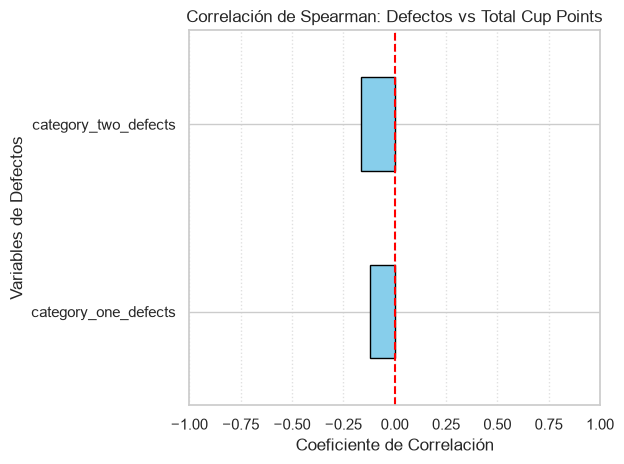

In [12]:
df_grupo1 = df_corr[['category_one_defects', 'category_two_defects']]
df_grupo2 = df_corr[['total_cup_points']]
matriz_cruzada = df_grupo1.corrwith(df_grupo2['total_cup_points'], method='spearman')


matriz_cruzada.plot(kind='barh', color='skyblue', edgecolor='black')

# Personalizar el diseño
plt.title("Correlación de Spearman: Defectos vs Total Cup Points")
plt.xlabel("Coeficiente de Correlación")
plt.ylabel("Variables de Defectos")
plt.xlim(-1, 1) # El rango de la correlación siempre va de -1 a 1
plt.axvline(0, color='red', linestyle='--') # Línea de referencia en 0
plt.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 4.1 Numérica – numérica: correlación - Conclusiones

> - Ambos tipos de defectos muestran una relación inversa esperada con
>   el puntaje final del café (a más defectos, menos puntos).
>   Sin embargo, el impacto de ambos es estadísticamente débil.
>
> - Los defectos secundarios o de categoría 2 (-0.16) penalizan el puntaje de taza un poco más que los defectos primarios de categoría 1 (-0.12).


### 4.2 Numérica – categórica: puntaje por país

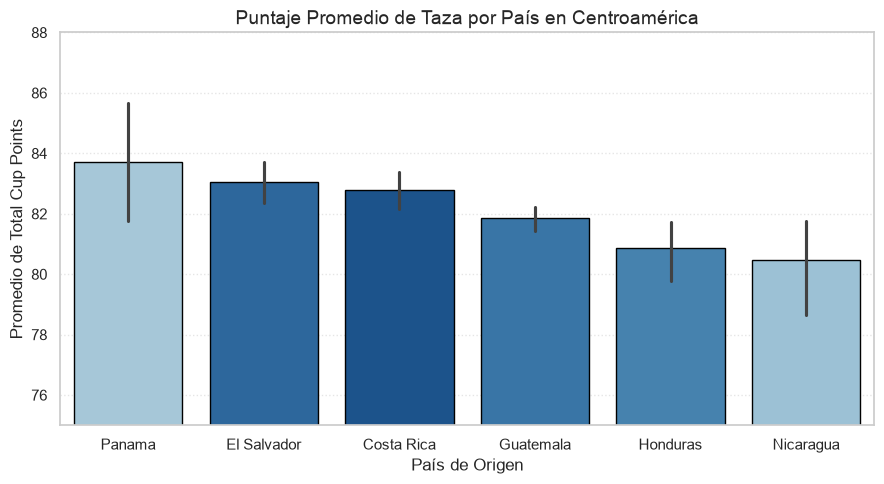

In [13]:
paises_ca = ["Honduras", "Costa Rica", "El Salvador", "Guatemala", "Nicaragua", "Panama"]
df_region = df[df['country_of_origin'].isin(paises_ca)]

plt.figure(figsize=(9, 5))
# Ordenamos las barras de mayor a menor promedio automáticamente
order = df_region.groupby('country_of_origin')['total_cup_points'].mean().sort_values(ascending=False).index

sns.barplot(
    data=df_region, 
    x='country_of_origin', 
    y='total_cup_points', 
    hue='country_of_origin',
    palette='Blues_r', 
    order=order, 
    dodge=False,
    legend=False, # <- Evita que se cree una leyenda redundante
    edgecolor='black'
)


plt.ylim(75, 88) 
plt.title("Puntaje Promedio de Taza por País en Centroamérica", fontsize=14)
plt.xlabel("País de Origen", fontsize=12)
plt.ylabel("Promedio de Total Cup Points", fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### 4.3 Numérica – categórica: (Histograma): Altitud Promedio por pais


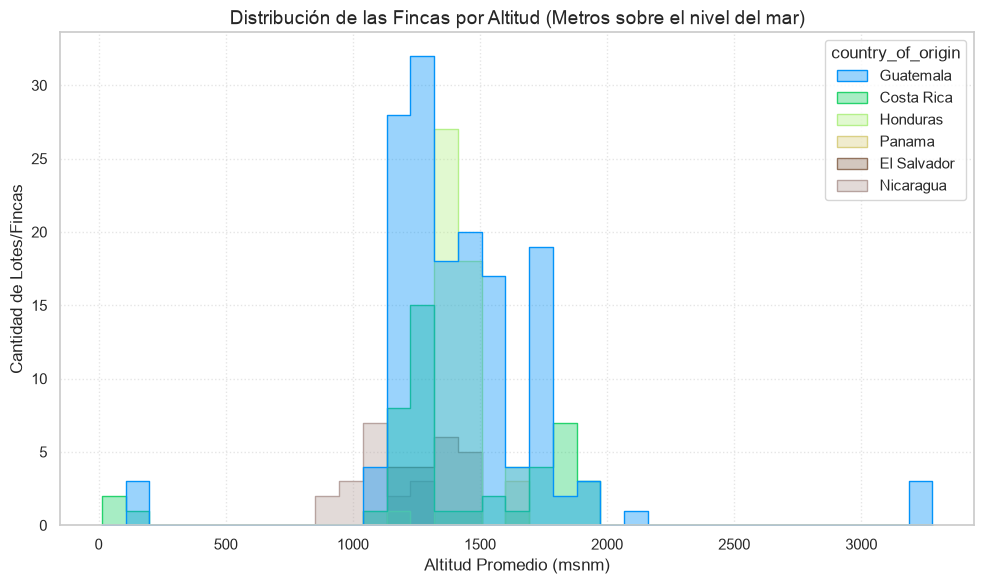

In [14]:


df_region['country_of_origin'] = df_region['country_of_origin'].astype(str)
df_altitud = df_region[df_region['altitude_mean_meters'] < 4000]

plt.figure(figsize=(10, 6))
sns.histplot(data=df_altitud, x='altitude_mean_meters', hue='country_of_origin', 
             element='step', stat='count', common_norm=False, palette='terrain', alpha=0.4)

plt.title("Distribución de las Fincas por Altitud (Metros sobre el nivel del mar)", fontsize=14)
plt.xlabel("Altitud Promedio (msnm)", fontsize=12)
plt.ylabel("Cantidad de Lotes/Fincas", fontsize=12)
plt.grid(axis='both', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

### 4.4 Numérica – categórica: (Boxplot): Intensidad de la Acidez (acidity) por País


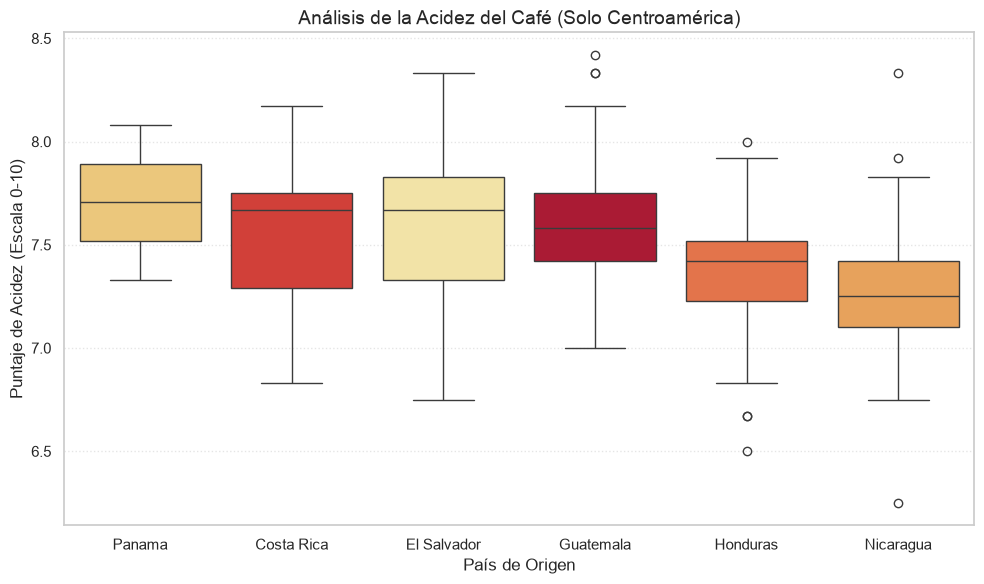

In [15]:
plt.figure(figsize=(10, 6))

# Calcular el orden usando el dataframe ya limpio
order_acidity = df_region.groupby('country_of_origin')['acidity'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_region, 
    x='country_of_origin', 
    y='acidity', 
    hue='country_of_origin', 
    palette='YlOrRd_r', 
    order=order_acidity,
    dodge=False,
    legend=False
)

plt.title("Análisis de la Acidez del Café (Solo Centroamérica)", fontsize=14)
plt.xlabel("País de Origen", fontsize=12)
plt.ylabel("Puntaje de Acidez (Escala 0-10)", fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


## 7. Conclusiones
Respondé brevemente cada pregunta guía con lo que encontraste:

1. **Distribución de la calidad:** …
2. **Atributos más asociados al puntaje:** …
3. **Altitud y calidad:** …
4. **Honduras vs. Centroamérica:** …
5. **Procesamiento y país:** …

### Limitaciones y próximos pasos
- Desbalance de especies (Arábica vs. Robusta)
- Faltantes en altitud y procesamiento
- Datos hasta 2018; los lotes los envían los productores (posible sesgo de selección)